In [2]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 20244080332

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"

print(f"[学号        ] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] conda1
[学号        ] 20244080332
[机器指纹] 59a04118ce1009ce
[RUN_ID] 20244080332-59a04118ce1009ce


In [ ]:
!conda install -n conda1 numpy matplotlib -y


In [8]:
import numpy as np
import matplotlib.pyplot as plt

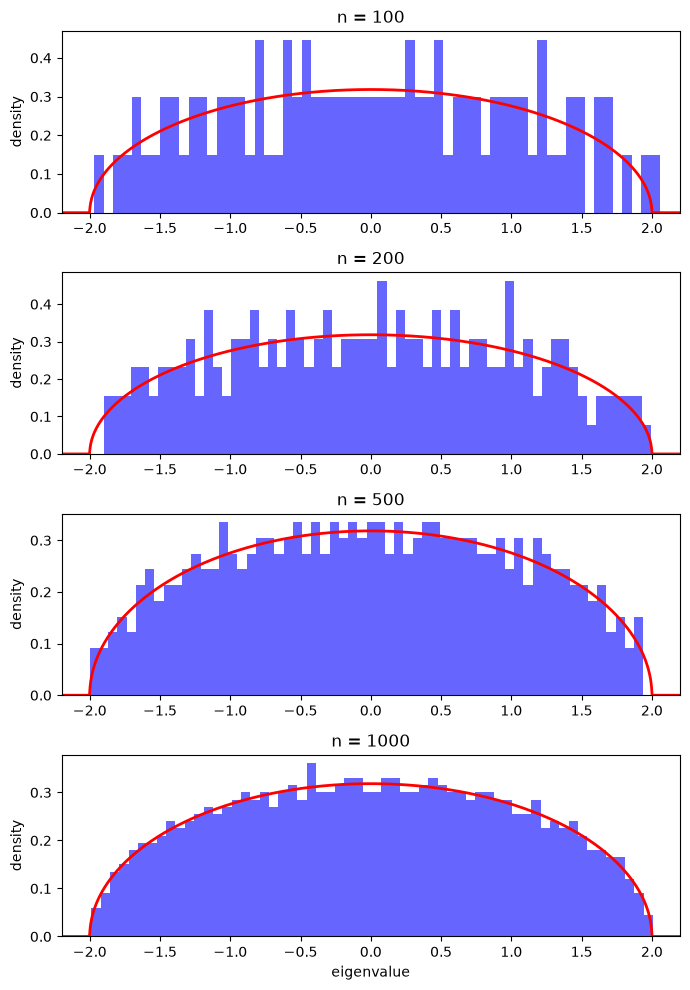

In [7]:
#一、围绕半圆规律
# 1：wigner_density(x)，计算半圆律密度，
def wigner_density(x):
    res = np.zeros_like(x, dtype=float)
    mask = np.abs(x) <= 2
    res[mask] = np.sqrt(4 - x[mask]**2) / (2 * np.pi)
    return float(res) if np.isscalar(x) else res

# 2：generate_wigner(n)，生成n阶Wigner对称随机矩阵，参数校验抛异常
def generate_wigner(n):
    if not isinstance(n, int):
        raise TypeError("n必须是整数")
    if n <= 0:
        raise ValueError("n必须是正整数")
    sigma = np.sqrt(1 / n)
    A = np.random.randn(n, n) * sigma
    return np.triu(A) + np.triu(A, 1).T

# 3：get_spectrum(matrix)，返回从小到大排序的特征值
def get_spectrum(mat):
    eig = np.linalg.eigvalsh(mat)
    eig.sort()
    return eig

# 4：绘制4张子图，n=100,200,500,1000，蓝色直方图+红色理论曲线
ns = [100, 200, 500, 1000]
fig, axes = plt.subplots(4, 1, figsize=(7, 10))
x = np.linspace(-2.2, 2.2, 1000)
y = wigner_density(x)

for ax, n in zip(axes, ns):
    ev = get_spectrum(generate_wigner(n))
    ax.hist(ev, bins=60, density=True, color="blue", alpha=0.6)
    ax.plot(x, y, c="red", lw=2)
    ax.set_title(f"n = {n}")
    ax.set_xlim(-2.2, 2.2)
    ax.set_ylabel("density")
axes[-1].set_xlabel("eigenvalue")
plt.tight_layout()
plt.show()


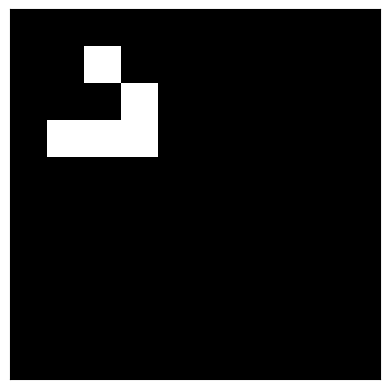

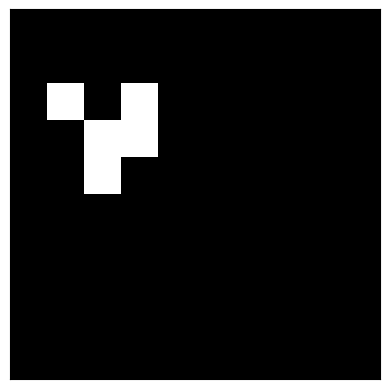

In [20]:
#二、Conway的生命游戏
# 1. 判断棋盘是否合法
def is_valid_board(board):
    # 必须是numpy二维数组，元素只能是0或1
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    unique_vals = np.unique(board)
    return set(unique_vals).issubset({0, 1})

# 2. 一步演化，环绕边界
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("棋盘不合法，必须是仅含0、1的二维numpy数组")
    m, n = board.shape
    next_board = np.zeros_like(board)
    # 环绕边界，用np.roll快速计算8邻域总和
    neighbor_sum = (
        np.roll(board, (1, 0), axis=(0, 1)) +
        np.roll(board, (-1, 0), axis=(0, 1)) +
        np.roll(board, (0, 1), axis=(0, 1)) +
        np.roll(board, (0, -1), axis=(0, 1)) +
        np.roll(board, (1, 1), axis=(0, 1)) +
        np.roll(board, (1, -1), axis=(0, 1)) +
        np.roll(board, (-1, 1), axis=(0, 1)) +
        np.roll(board, (-1, -1), axis=(0, 1))
    )
    # 活细胞规则
    alive = board == 1
    next_board[alive & (neighbor_sum == 2)] = 1
    next_board[alive & (neighbor_sum == 3)] = 1
    # 死细胞复活规则
    dead = board == 0
    next_board[dead & (neighbor_sum == 3)] = 1
    return next_board

# 3. 绘图函数，无坐标轴、无网格
def draw_gol_board(board):
    plt.figure()
    plt.imshow(board, cmap=plt.get_cmap('binary_r'))
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.show()

# 滑翔机测试
glider = np.array([
    [0,1,0],
    [0,0,1],
    [1,1,1]
])
board = np.zeros((10,10),dtype=int)
board[1:4,1:4] = glider
draw_gol_board(board)
board = gol_step(board)
draw_gol_board(board)


In [ ]:
!conda install pandas -y

In [ ]:
!pip install scikit-learn

In [33]:
#三、pandas
import pandas as pd
from sklearn.datasets import load_iris

# 1.加载iris，转成DataFrame
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = [iris.target_names[i] for i in iris.target]

# 修改列名，和kaggle这个iris.csv保持一致
df.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]

# =========  输出题目要求信息 =========
print("数据点数量：", len(df))
print("\n各列数据类型：")
print(df.dtypes)
print("\n列名：")
print(df.columns.tolist())
print("\n花卉种类：")
species_unique = df["species"].unique()
print(species_unique)
print("花卉种类数量：", len(species_unique))

#2. 修改两行（索引34、37，对应题目35、38行）
df.loc[34] = [4.9, 3.1, 1.5, 0.2, "setosa"]
df.loc[37] = [4.9, 3.6, 1.4, 0.1, "setosa"]
print("\n修改后的34行：")
print(df.loc[34])
print("\n修改后的37行：")
print(df.loc[37])

#3. 添加两列比值
df["Petal.Ratio"] = df["petal_length"] / df["petal_width"]
df["Sepal.Ratio"] = df["sepal_length"] / df["sepal_width"]

# 4. 保存文件
df.to_csv("iris_corrected.csv", index=False)

#  5. 分组聚合
agg_funcs = ["mean", "median", "min", "max", "std"]
result = df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(agg_funcs)
print("\n分组统计结果：")
print(result)


数据点数量： 150

各列数据类型：
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

列名：
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

花卉种类：
<StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str
花卉种类数量： 3

修改后的34行：
sepal_length       4.9
sepal_width        3.1
petal_length       1.5
petal_width        0.2
species         setosa
Name: 34, dtype: object

修改后的37行：
sepal_length       4.9
sepal_width        3.6
petal_length       1.4
petal_width        0.1
species         setosa
Name: 37, dtype: object

分组统计结果：
           Petal.Ratio                                     Sepal.Ratio  \
                  mean    median       min   max       std        mean   
species                                                                  
setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.470188   
versicolor    3.242837  3.240385  2.666667   4.1  0.312456    2.160402   